# Geometry + Colorimetry Fusion: Pre / Per / Post-Exercise Classification

This notebook combines the two approaches previously tested:
- **Colorimetry** (`colorimetry` notebook): 7 best features (selected based on Random Forest feature importance).
- **Facial Geometry** (`geometric-features` notebook): 3 best features (mouth-related features).



## 1 - Library

In [1]:
import urllib.request
from pathlib import Path

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

# ---------- Paramètres ----------
DOSSIER = Path("../dataset_computervision_LECSIN/dataset_squat")   # à adapter si besoin
GROUPES = ["pre", "per", "post"]
SEED = 42
ROI_RATIO = 0.6            # fraction centrale du visage utilisée pour la colorimétrie
Path("figures").mkdir(exist_ok=True)

# ---------- Features retenues (top issus des deux notebooks) ----------
TOP_COULEUR = ["scene_pixels_valides_pct", "gw_face_corr_bg", "moyenne_srgb_R",
               "contraste_rms", "ratio_lum_visage_scene", "face_y", "gw_dist_A"]   # top 7 colorimétrie
TOP_GEO = ["mouth_opening_ratio", "mouth_corner_angle_deg", "mouth_edge_density"]   # top 3 géométrie
TOP_FUSION = TOP_COULEUR + TOP_GEO

# Features qui dépendent de la scène (fond / éclairage) et pas seulement du visage
FEATURES_SCENE = ["scene_pixels_valides_pct", "gw_face_corr_bg",
                  "ratio_lum_visage_scene", "gw_dist_A"]
TOP_FUSION_SANS_SCENE = [f for f in TOP_FUSION if f not in FEATURES_SCENE]

SOURCE = {**{f: "colorimétrie" for f in TOP_COULEUR}, **{f: "géométrie" for f in TOP_GEO}}

## 2 - Features Function

### 2.1 Face Detection (Viola-Jones)

In [2]:
_CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
if _CASCADE.empty():
    raise RuntimeError("Cascade non chargée : vérifie l'installation d'OpenCV")


def detecter_visage(img, scale_factor=1.1, min_neighbors=5, min_size=(60, 60)):
    """Input : image BGR. Output : bbox (x, y, w, h) du plus grand visage, ou None."""
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    visages = _CASCADE.detectMultiScale(gris, scaleFactor=scale_factor,
                                        minNeighbors=min_neighbors, minSize=min_size)
    if len(visages) == 0:
        return None
    x, y, w, h = max(visages, key=lambda b: b[2] * b[3])
    return int(x), int(y), int(w), int(h)


def recadrer(img, bbox, roi_ratio=1.0):
    """Recadre la boîte (roi_ratio=1.0 : visage entier ; 0.6 : centre du visage)."""
    x, y, w, h = bbox
    dx, dy = int(w * (1 - roi_ratio) / 2), int(h * (1 - roi_ratio) / 2)
    return img[y + dy : y + h - dy, x + dx : x + w - dx]

### 2.2 Colorimetric features

In [3]:
CANAUX = ("B", "G", "R")   # ordre OpenCV

_niveaux = np.arange(256, dtype=np.float32) / 255.0
_LUT_LIN_U8 = np.where(_niveaux <= 0.04045, _niveaux / 12.92,
                       ((_niveaux + 0.055) / 1.055) ** 2.4).astype(np.float32)


def _valeur_max(img):
    return float(np.iinfo(img.dtype).max) if np.issubdtype(img.dtype, np.integer) else 1.0


def normaliser(img):
    """Image BGR -> float32 dans [0, 1] (valeurs sRGB)."""
    return img.astype(np.float32) * np.float32(1.0 / _valeur_max(img))


def srgb_vers_lineaire(img_bgr):
    """Image BGR -> lumière linéaire float32 dans [0, 1]."""
    if img_bgr.dtype == np.uint8:
        return cv2.LUT(img_bgr, _LUT_LIN_U8)
    c = normaliser(img_bgr)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4).astype(np.float32)


def _luminance(bgr_norm):
    return 0.0722 * bgr_norm[..., 0] + 0.7152 * bgr_norm[..., 1] + 0.2126 * bgr_norm[..., 2]


def feature_gamma(srgb, lin, luma, lum_lin):
    m_srgb = srgb.reshape(-1, 3).mean(axis=0, dtype=np.float64)
    m_lin = lin.reshape(-1, 3).mean(axis=0, dtype=np.float64)
    feats = {}
    for i, nom in enumerate(CANAUX):
        feats[f"moyenne_srgb_{nom}"] = float(m_srgb[i])
        feats[f"moyenne_lin_{nom}"] = float(m_lin[i])
    feats["luma_srgb_moy"] = float(luma.mean(dtype=np.float64))
    feats["luminance_lin_moy"] = float(lum_lin.mean(dtype=np.float64))
    return feats


def feature_plage_dynamique(luma, lum_lin, eps=1e-4):
    luma, lum_lin = luma.ravel(), lum_lin.ravel()
    p1, p99 = np.percentile(lum_lin, [1, 99])
    l1, l99 = np.percentile(luma, [1, 99])
    return {
        "luma_min": float(luma.min()), "luma_max": float(luma.max()),
        "luma_p1": float(l1), "luma_p99": float(l99),
        "etendue_p1_p99": float(l99 - l1),
        "plage_dynamique_stops": float(np.log2((p99 + eps) / (p1 + eps))),
        "contraste_rms": float(luma.std(dtype=np.float64)),
        "contraste_michelson": float((l99 - l1) / (l99 + l1 + 1e-9)),
        "pct_sature": float(100 * np.mean(luma >= 0.98)),
        "pct_sous_expose": float(100 * np.mean(luma <= 0.02)),
    }


# ---------- Lumière : illuminant, température de couleur, constance des couleurs ----------
M_RGB2XYZ = np.array([[0.4124564, 0.3575761, 0.1804375],
                      [0.2126729, 0.7151522, 0.0721750],
                      [0.0193339, 0.1191920, 0.9503041]])
ILLUMINANTS_XY = {"D65": (0.3127, 0.3290), "D50": (0.3457, 0.3585), "A": (0.4476, 0.4074)}


def _rgb_vers_xy(rgb):
    X, Y, Z = M_RGB2XYZ @ np.asarray(rgb, dtype=np.float64)
    s = X + Y + Z + 1e-12
    return X / s, Y / s


def _cct_mccamy(x, y):
    den = 0.1858 - y
    if abs(den) < 1e-6:
        den = 1e-6
    n = (x - 0.3320) / den
    return float(np.clip(449 * n ** 3 + 3525 * n ** 2 + 6823.3 * n + 5520.33, 1500, 15000))


def _masque_scene(img, bbox=None, bas=0.02, haut=0.98):
    vmax = _valeur_max(img)
    masque = np.all((img > bas * vmax) & (img < haut * vmax), axis=2)
    if bbox is not None:
        x0, y0, x1, y1 = bbox
        masque[y0:y1, x0:x1] = False
    return masque


def feature_lumiere(img, visage_lin, bbox, taille_scene=320, eps=1e-6):
    """img : image BGR entière ; visage_lin : ROI visage en linéaire ; bbox : boîte Viola-Jones."""
    h_img, w_img = img.shape[:2]
    echelle = min(1.0, taille_scene / max(h_img, w_img))
    petit = (cv2.resize(img, (max(1, round(w_img * echelle)), max(1, round(h_img * echelle))),
                        interpolation=cv2.INTER_AREA) if echelle < 1.0 else img)
    sx, sy = petit.shape[1] / w_img, petit.shape[0] / h_img

    x, y, w, h = bbox
    bbox_p = (int(x * sx), int(y * sy), int(np.ceil((x + w) * sx)), int(np.ceil((y + h) * sy)))

    masque = _masque_scene(petit, bbox_p)
    if masque.sum() < 5000 * sx * sy:                      # scène trop petite : repli image entière
        masque = _masque_scene(petit, None)
    lin_scene = srgb_vers_lineaire(petit)
    pixels = lin_scene[masque][:, ::-1]                    # ordre RGB
    if len(pixels) == 0:
        pixels = lin_scene.reshape(-1, 3)[:, ::-1]
    pixels_moy = pixels.mean(axis=0, dtype=np.float64)
    lin_visage = visage_lin.reshape(-1, 3).mean(axis=0, dtype=np.float64)[::-1]

    feats = {"scene_pixels_valides_pct": float(100 * masque.mean())}
    fx, fy = _rgb_vers_xy(lin_visage)
    feats["face_rg"] = float(lin_visage[0] / max(lin_visage[1], eps))
    feats["face_bg"] = float(lin_visage[2] / max(lin_visage[1], eps))
    feats["face_x"], feats["face_y"] = float(fx), float(fy)
    feats["face_cct"] = _cct_mccamy(fx, fy)

    estimations = {"gw": pixels_moy, "wp": np.percentile(pixels, 99, axis=0)}
    for nom, e in estimations.items():
        e = np.maximum(np.asarray(e, dtype=np.float64), eps)
        feats[f"{nom}_rg"], feats[f"{nom}_bg"] = float(e[0] / e[1]), float(e[2] / e[1])
        x_, y_ = _rgb_vers_xy(e)
        feats[f"{nom}_cct"] = _cct_mccamy(x_, y_)
        corr = lin_visage * (e[1] / e)
        feats[f"{nom}_face_corr_rg"] = float(corr[0] / max(corr[1], eps))
        feats[f"{nom}_face_corr_bg"] = float(corr[2] / max(corr[1], eps))
        if nom == "gw":
            for ill, (xi, yi) in ILLUMINANTS_XY.items():
                feats[f"gw_dist_{ill}"] = float(np.hypot(x_ - xi, y_ - yi))
    feats["ecart_gw_wp"] = abs(feats["gw_rg"] - feats["wp_rg"]) + abs(feats["gw_bg"] - feats["wp_bg"])

    lum = lambda c: 0.2126 * c[0] + 0.7152 * c[1] + 0.0722 * c[2]
    feats["ratio_lum_visage_scene"] = float(lum(lin_visage) / (lum(pixels_moy) + eps))
    return feats


def colorimetry(img, bbox, roi_ratio=ROI_RATIO):
    """Input : image BGR + bbox du visage. Output : dict de features colorimétriques."""
    roi = recadrer(img, bbox, roi_ratio)
    v_srgb, v_lin = normaliser(roi), srgb_vers_lineaire(roi)
    luma, lum_lin = _luminance(v_srgb), _luminance(v_lin)
    feats = {}
    feats.update(feature_gamma(v_srgb, v_lin, luma, lum_lin))
    feats.update(feature_plage_dynamique(luma, lum_lin))
    feats.update(feature_lumiere(img, v_lin, bbox))
    return feats

### 2.3 Geometric features (MediaPipe FaceLandmarker + contours)

In [4]:
def retirer_fond(visage, iterations=1):
    """Remplace le fond du recadrage visage par sa couleur médiane (GrabCut)."""
    h, w = visage.shape[:2]
    masque = np.full((h, w), cv2.GC_PR_BGD, dtype=np.uint8)
    bord = max(2, int(min(h, w) * 0.04))
    masque[bord:-bord, bord:-bord] = cv2.GC_PR_FGD
    cv2.ellipse(masque, (w // 2, h // 2), (int(w * 0.42), int(h * 0.48)), 0, 0, 360, cv2.GC_FGD, -1)
    cv2.grabCut(visage, masque, None, np.zeros((1, 65)), np.zeros((1, 65)),
                iterations, cv2.GC_INIT_WITH_MASK)
    avant = np.isin(masque, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8)
    noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    avant = cv2.morphologyEx(cv2.morphologyEx(avant, cv2.MORPH_CLOSE, noyau), cv2.MORPH_OPEN, noyau)
    pixels_bord = np.concatenate((visage[:bord].reshape(-1, 3), visage[-bord:].reshape(-1, 3)))
    propre = np.broadcast_to(np.median(pixels_bord, axis=0).astype(np.uint8), visage.shape).copy()
    propre[avant > 0] = visage[avant > 0]
    return propre


_MODELE_LANDMARKS = Path("models/face_landmarker.task")
_URL_LANDMARKS = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
                  "face_landmarker/float16/1/face_landmarker.task")
if not _MODELE_LANDMARKS.exists():
    _MODELE_LANDMARKS.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(_URL_LANDMARKS, _MODELE_LANDMARKS)
_LANDMARKER = mp.tasks.vision.FaceLandmarker.create_from_options(
    mp.tasks.vision.FaceLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=str(_MODELE_LANDMARKS)),
        running_mode=mp.tasks.vision.RunningMode.IMAGE, num_faces=1,
        min_face_detection_confidence=0.5, min_face_presence_confidence=0.5))

_GROUPES_LANDMARKS = {
    "oeil_g": [33, 160, 158, 133, 153, 144],
    "oeil_d": [362, 385, 387, 263, 373, 380],
    "bouche_ext": [61, 146, 91, 181, 84, 17, 314, 405, 321, 375, 291, 409, 270, 269, 267, 0, 37, 39, 40],
    "bouche_int": [78, 95, 88, 178, 87, 14, 317, 402, 318, 324, 308, 415, 310, 311, 312, 13, 82, 81],
}


def _points_landmarks(visage):
    rgb = cv2.cvtColor(visage, cv2.COLOR_BGR2RGB)
    res = _LANDMARKER.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.face_landmarks:
        return None
    h, w = visage.shape[:2]
    pts = np.array([(l.x * w, l.y * h) for l in res.face_landmarks[0]], dtype=np.float32)
    return pts if np.isfinite(pts).all() else None


def _dist(p, a, b):
    return float(np.linalg.norm(p[a] - p[b]))


def _aire(poly):
    return float(abs(cv2.contourArea(poly.astype(np.float32))))


def _roi_rel(gris, x0, y0, x1, y1):
    h, w = gris.shape[:2]
    return gris[int(h * y0):int(h * y1), int(w * x0):int(w * x1)]


def geometrie(visage):
    """Input : recadrage BGR du visage (fond retiré).
    Output : (dict de features géométriques, landmarks_ok)."""
    h, w = visage.shape[:2]
    gris = cv2.cvtColor(visage, cv2.COLOR_BGR2GRAY)
    pts = _points_landmarks(visage)
    feats = {}

    if pts is not None:
        inter = max(_dist(pts, 33, 263), 1.0)                       # distance inter-oculaire (normalisation)
        lw, rw = _dist(pts, 33, 133) / inter, _dist(pts, 362, 263) / inter
        lh = np.mean([_dist(pts, 160, 144), _dist(pts, 158, 153)]) / inter
        rh = np.mean([_dist(pts, 385, 380), _dist(pts, 387, 373)]) / inter
        bw, bh = _dist(pts, 61, 291) / inter, _dist(pts, 13, 14) / inter
        g = {k: pts[np.asarray(v, dtype=int)] for k, v in _GROUPES_LANDMARKS.items()}
        feats.update({
            "eye_left_opening_ratio": float(lh / max(lw, 1e-6)),
            "eye_right_opening_ratio": float(rh / max(rw, 1e-6)),
            "eye_opening_asymmetry": float(abs(lh - rh)),
            "eye_left_width": float(lw), "eye_left_height": float(lh),
            "eye_right_width": float(rw), "eye_right_height": float(rh),
            "eye_left_area": _aire(g["oeil_g"]) / inter ** 2,
            "eye_right_area": _aire(g["oeil_d"]) / inter ** 2,
            "mouth_opening_ratio": float(bh / max(bw, 1e-6)),
            "mouth_width": float(bw), "mouth_height": float(bh),
            "mouth_outer_area": _aire(g["bouche_ext"]) / inter ** 2,
            "mouth_inner_area": _aire(g["bouche_int"]) / inter ** 2,
            "mouth_corner_angle_deg": float(np.degrees(np.arctan2(
                pts[13, 1] - (pts[61, 1] + pts[291, 1]) / 2, max(_dist(pts, 61, 291), 1.0)))),
        })

    # Densité de contours (Canny) : mêmes zones que le notebook géométrique
    canny = lambda r: float(np.mean(cv2.Canny(r, 30, 100) > 0))
    bords = cv2.Canny(gris, 30, 100)
    moitie = w // 2
    gauche = bords[:, :moitie].astype(float)
    droite = np.fliplr(bords[:, w - moitie:].astype(float))
    d_og = canny(_roi_rel(gris, 0.08, 0.22, 0.52, 0.62))
    d_od = canny(_roi_rel(gris, 0.48, 0.22, 0.92, 0.62))
    feats.update({
        "eye_left_edge_density": d_og, "eye_right_edge_density": d_od,
        "eye_edge_density_asymmetry": abs(d_og - d_od),
        "mouth_edge_density": canny(_roi_rel(gris, 0.16, 0.48, 0.84, 0.96)),
        "face_edge_density": float(np.mean(bords > 0)),
        "left_right_edge_asymmetry": float(np.mean(np.abs(gauche - droite)) / 255.0),
    })
    return feats, pts is not None

### 2.4 Fusion function : image → colorimetric + geometric features

In [5]:
def extraire_features(chemin):
    """Input : chemin d'image. Output : dict {features couleur + géométrie}, ou None si échec
    (image illisible, aucun visage Viola-Jones, ou landmarks MediaPipe introuvables)."""
    img = cv2.imread(str(chemin))
    if img is None:
        raise FileNotFoundError(f"Image illisible : {chemin}")
    bbox = detecter_visage(img)                       # détection unique, partagée par les deux méthodes
    if bbox is None:
        return None

    feats_c = colorimetry(img, bbox, roi_ratio=ROI_RATIO)               # centre du visage (60 %)
    visage_complet = retirer_fond(recadrer(img, bbox, roi_ratio=1.0))   # visage entier, fond neutralisé
    feats_g, landmarks_ok = geometrie(visage_complet)
    if not landmarks_ok:
        return None
    return {**feats_c, **feats_g}

### 2.5 Train / Validation / Test Split and Feature Extraction on the Entire Dataset

In [6]:
# Inventaire + split aléatoire stratifié 60 / 20 / 20 (identique aux deux notebooks d'origine)
fichiers = pd.DataFrame([
    {"chemin": str(c), "groupe": g}
    for g in GROUPES for c in sorted((DOSSIER / f"squat_{g}").glob("*.jpg"))
])
trainval, test = train_test_split(fichiers, test_size=0.20, stratify=fichiers["groupe"], random_state=SEED)
train, val = train_test_split(trainval, test_size=0.25, stratify=trainval["groupe"], random_state=SEED)

assert not (set(train["chemin"]) & set(val["chemin"]))
assert not (set(train["chemin"]) & set(test["chemin"]))
assert not (set(val["chemin"]) & set(test["chemin"]))
splits = pd.concat([train.assign(jeu="train"), val.assign(jeu="val"), test.assign(jeu="test")])

# Extraction (on ne calcule qu'une fois, puis on réutilise le CSV)
lignes, ecartees = [], 0
for ligne in splits.itertuples(index=False):
    feats = extraire_features(ligne.chemin)
    if feats is None:
        ecartees += 1
        continue
    lignes.append({"chemin": ligne.chemin, "groupe": ligne.groupe, "jeu": ligne.jeu, **feats})

data = pd.DataFrame(lignes)
data.to_csv("features_fusion.csv", index=False)

print(f"{len(data)} images exploitables, {ecartees} écartées (pas de visage ou pas de landmarks)")
print(pd.crosstab(data["jeu"], data["groupe"]).loc[["train", "val", "test"], GROUPES])

1457 images exploitables, 43 écartées (pas de visage ou pas de landmarks)
groupe  pre  per  post
jeu                   
train   289  292   288
val      98   99    99
test     96   98    98


## 3 - Model

In [7]:
# Jeux de features comparés : les deux méthodes seules, la fusion, et la fusion sans features de scène
JEUX_FEATURES = {
    "Colorimétrie (7)": TOP_COULEUR,
    "Géométrie (3)": TOP_GEO,
    "Fusion (10)": TOP_FUSION,
    f"Fusion sans scène ({len(TOP_FUSION_SANS_SCENE)})": TOP_FUSION_SANS_SCENE,
}

manquantes = [f for f in TOP_FUSION if f not in data.columns]
assert not manquantes, f"Features absentes du dataset : {manquantes}"


def creer_modeles():
    """Nouveaux modèles à chaque appel (pas d'état partagé entre jeux de features)."""
    return {
        "Baseline (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
        "Régression logistique": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    }

MODELE_FINAL = "Random Forest"   # modèle explicable retenu pour la fusion

## 4 - Training

In [8]:
d_train, d_val, d_test = (data[data["jeu"] == j] for j in ("train", "val", "test"))
y_train, y_val, y_test = d_train["groupe"], d_val["groupe"], d_test["groupe"]

# 1) Comparaison sur la VALIDATION : chaque modèle x chaque jeu de features
lignes = []
for nom_jeu, feats in JEUX_FEATURES.items():
    for nom_modele, modele in creer_modeles().items():
        modele.fit(d_train[feats], y_train)
        pred = modele.predict(d_val[feats])
        lignes.append({"jeu_features": nom_jeu, "modele": nom_modele,
                       "accuracy_val": accuracy_score(y_val, pred),
                       "balanced_acc_val": balanced_accuracy_score(y_val, pred)})
scores_val = pd.DataFrame(lignes)
print(scores_val.pivot(index="modele", columns="jeu_features", values="balanced_acc_val").round(3))

# 2) Modèles finaux : réentraînés sur train + val (un par jeu de features)
X_trainval = pd.concat([d_train, d_val])
y_trainval = pd.concat([y_train, y_val])
modeles_finaux = {}
for nom_jeu, feats in JEUX_FEATURES.items():
    modele = creer_modeles()[MODELE_FINAL]
    modele.fit(X_trainval[feats], y_trainval)
    modeles_finaux[nom_jeu] = modele
print(f"\nModèles finaux ({MODELE_FINAL}) entraînés sur train + val : {list(modeles_finaux)}")

jeu_features                   Colorimétrie (7)  Fusion (10)  \
modele                                                         
Baseline (classe majoritaire)             0.333        0.333   
Random Forest                             0.997        0.997   
Régression logistique                     0.939        0.986   

jeu_features                   Fusion sans scène (6)  Géométrie (3)  
modele                                                               
Baseline (classe majoritaire)                  0.333          0.333  
Random Forest                                  0.983          0.862  
Régression logistique                          0.851          0.624  

Modèles finaux (Random Forest) entraînés sur train + val : ['Colorimétrie (7)', 'Géométrie (3)', 'Fusion (10)', 'Fusion sans scène (6)']


## 5 - Results

                       n_features  accuracy  balanced_accuracy
jeu_features                                                  
Colorimétrie (7)                7     1.000              1.000
Géométrie (3)                   3     0.887              0.887
Fusion (10)                    10     1.000              1.000
Fusion sans scène (6)           6     0.962              0.962


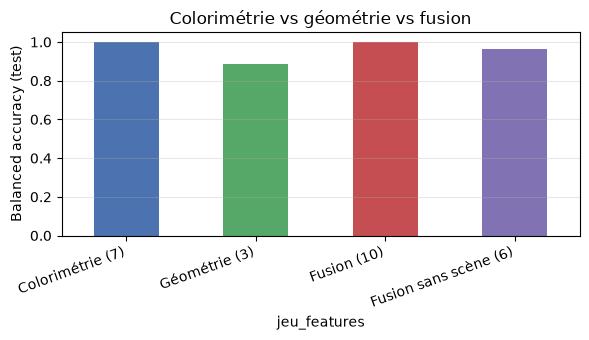


--- Fusion (10 features) ---
              precision    recall  f1-score   support

         pre       1.00      1.00      1.00        96
         per       1.00      1.00      1.00        98
        post       1.00      1.00      1.00        98

    accuracy                           1.00       292
   macro avg       1.00      1.00      1.00       292
weighted avg       1.00      1.00      1.00       292



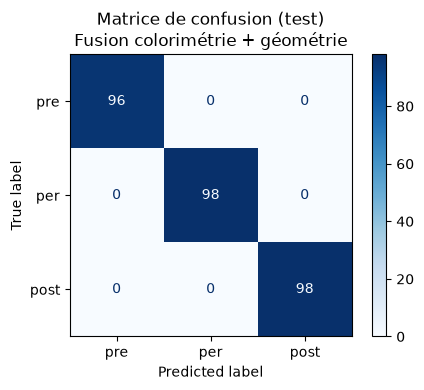

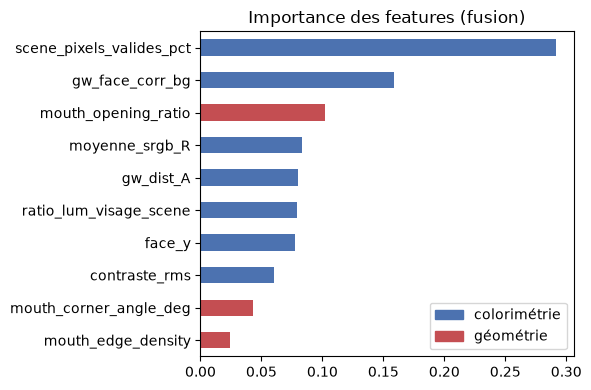

Part d'importance par méthode :
 colorimétrie    0.83
géométrie       0.17


In [9]:
# Évaluation finale sur le TEST (une seule fois)
lignes, preds = [], {}
for nom_jeu, feats in JEUX_FEATURES.items():
    pred = modeles_finaux[nom_jeu].predict(d_test[feats])
    preds[nom_jeu] = pred
    lignes.append({"jeu_features": nom_jeu, "n_features": len(feats),
                   "accuracy": accuracy_score(y_test, pred),
                   "balanced_accuracy": balanced_accuracy_score(y_test, pred)})
resume = pd.DataFrame(lignes).set_index("jeu_features").round(3)
print(resume)

fig, ax = plt.subplots(figsize=(6, 3.5))
resume["balanced_accuracy"].plot.bar(ax=ax, color=["#4C72B0", "#55A868", "#C44E52", "#8172B3"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Balanced accuracy (test)"); ax.grid(axis="y", alpha=.3)
ax.set_title("Colorimétrie vs géométrie vs fusion"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.savefig("figures/comparaison_fusion.png", dpi=150, bbox_inches="tight"); plt.show()

# Rapport détaillé + matrice de confusion de la fusion
print("\n--- Fusion (10 features) ---")
print(classification_report(y_test, preds["Fusion (10)"], labels=GROUPES, zero_division=0))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, preds["Fusion (10)"], labels=GROUPES, cmap="Blues", ax=ax)
ax.set_title("Matrice de confusion (test)\nFusion colorimétrie + géométrie")
plt.tight_layout(); plt.savefig("figures/confusion_fusion.png", dpi=150, bbox_inches="tight"); plt.show()

# Importance des features dans le modèle fusionné
rf = modeles_finaux["Fusion (10)"]
imp = pd.Series(rf.feature_importances_, index=TOP_FUSION).sort_values()
couleurs = ["#4C72B0" if SOURCE[f] == "colorimétrie" else "#C44E52" for f in imp.index]
fig, ax = plt.subplots(figsize=(6, 4))
imp.plot.barh(ax=ax, color=couleurs, title="Importance des features (fusion)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#4C72B0"), plt.Rectangle((0, 0), 1, 1, color="#C44E52")],
          labels=["colorimétrie", "géométrie"], loc="lower right")
plt.tight_layout(); plt.savefig("figures/importance_fusion.png", dpi=150, bbox_inches="tight"); plt.show()

part = imp.groupby(imp.index.map(SOURCE)).sum().round(3)
print("Part d'importance par méthode :\n", part.to_string())

### Selected Model: Scene-Free Fusion (6)

Selected because it uses only facial features (no background or lighting features), making it more likely to generalize to new videos and individuals. It performs significantly better than facial geometry alone.

Modèle retenu : Fusion sans scène (6)
Features (6) : ['moyenne_srgb_R', 'contraste_rms', 'face_y', 'mouth_opening_ratio', 'mouth_corner_angle_deg', 'mouth_edge_density']
Accuracy test          : 0.962
Balanced accuracy test : 0.962

              precision    recall  f1-score   support

         pre       0.98      0.97      0.97        96
         per       0.94      0.98      0.96        98
        post       0.97      0.94      0.95        98

    accuracy                           0.96       292
   macro avg       0.96      0.96      0.96       292
weighted avg       0.96      0.96      0.96       292



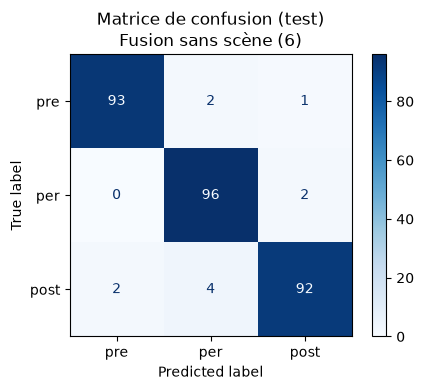

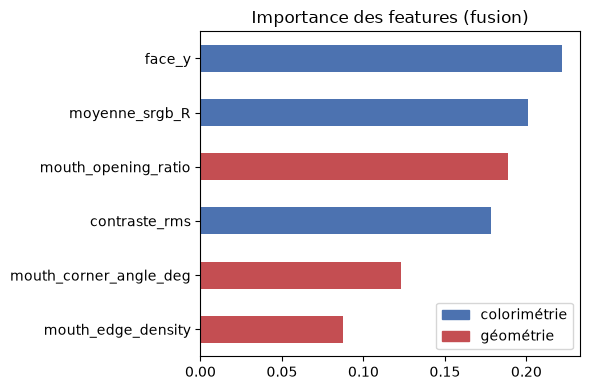

Part d'importance par méthode :
 colorimétrie    0.601
géométrie       0.399
Modèle sauvegardé : models/fusion_sans_scene_rf.joblib


In [15]:
import joblib

MODELE_CHOISI_NOM = f"Fusion sans scène ({len(TOP_FUSION_SANS_SCENE)})"
modele_choisi = modeles_finaux[MODELE_CHOISI_NOM]
features_choisies = JEUX_FEATURES[MODELE_CHOISI_NOM]
pred_choisi = preds[MODELE_CHOISI_NOM]

print(f"Modèle retenu : {MODELE_CHOISI_NOM}")
print(f"Features ({len(features_choisies)}) : {features_choisies}")
print(f"Accuracy test          : {accuracy_score(y_test, pred_choisi):.3f}")
print(f"Balanced accuracy test : {balanced_accuracy_score(y_test, pred_choisi):.3f}\n")
print(classification_report(y_test, pred_choisi, labels=GROUPES, zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_choisi, labels=GROUPES, cmap="Blues", ax=ax)
ax.set_title(f"Matrice de confusion (test)\n{MODELE_CHOISI_NOM}")
plt.tight_layout(); plt.savefig("figures/confusion_modele_choisi.png", dpi=150, bbox_inches="tight"); plt.show()

# Sauvegarde pour la suite (analyse temporelle, nouvelles images)
Path("models").mkdir(exist_ok=True)
joblib.dump({"modele": modele_choisi, "features": features_choisies,
             "classes": list(modele_choisi.classes_), "roi_ratio": ROI_RATIO},
            "models/fusion_sans_scene_rf.joblib")


# Importance des features dans le modèle fusionné
rf = modeles_finaux[MODELE_CHOISI_NOM]
imp = pd.Series(rf.feature_importances_, index=features_choisies).sort_values()
couleurs = ["#4C72B0" if SOURCE[f] == "colorimétrie" else "#C44E52" for f in imp.index]
fig, ax = plt.subplots(figsize=(6, 4))
imp.plot.barh(ax=ax, color=couleurs, title="Importance des features (fusion)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#4C72B0"), plt.Rectangle((0, 0), 1, 1, color="#C44E52")],
          labels=["colorimétrie", "géométrie"], loc="lower right")
plt.tight_layout(); plt.savefig("figures/importance_fusion.png", dpi=150, bbox_inches="tight"); plt.show()
part = imp.groupby(imp.index.map(SOURCE)).sum().round(3)
print("Part d'importance par méthode :\n", part.to_string())


print("Modèle sauvegardé : models/fusion_sans_scene_rf.joblib")

In [11]:
def tester_image(chemin, jeu=None):
    """Classe une image (pre / per / post) avec le modèle retenu (fusion sans scène) et affiche les probabilités."""
    jeu = jeu or MODELE_CHOISI_NOM
    feats = extraire_features(chemin)
    if feats is None:
        print("Image non exploitable (aucun visage ou landmarks introuvables).")
        return None
    cols = JEUX_FEATURES[jeu]
    X = pd.DataFrame([feats])[cols]
    modele = modeles_finaux[jeu]
    pred = modele.predict(X)[0]
    proba = pd.Series(modele.predict_proba(X)[0], index=modele.classes_).reindex(GROUPES)

    img = cv2.cvtColor(cv2.imread(str(chemin)), cv2.COLOR_BGR2RGB)
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(img); axes[0].axis("off")
    proba.plot.bar(ax=axes[1], color=["#4C72B0", "#55A868", "#C44E52"]); axes[1].set_ylim(0, 1)
    axes[1].tick_params(axis="x", rotation=0); axes[1].set_title("Probabilités par classe")
    plt.suptitle(f"{Path(chemin).name}  ->  {pred.upper()}")
    plt.tight_layout(); plt.show()
    return pred

# Exemple : tester_image(d_test["chemin"].iloc[0])